
# Model Development and Optimisation — Results Summary

Several machine learning classification algorithms were evaluated and optimised to predict earthworm acute toxicity.

Random Forest was selected as the best-performing candidate model, with the following results:

- **Training Accuracy:** 0.83
- **Test Accuracy:** 0.54
- **Test Sensitivity:** 0.36
- **Test Specificity:** 0.71
- **Cross-validation Accuracy:** 0.512 ± 0.024

**Interpretation:** The model demonstrated reasonable training performance but limited generalisation to the test dataset. The low sensitivity indicates difficulty identifying toxic chemicals, suggesting potential overfitting and a need for further optimisation.

**Conclusion:** Additional validation, verification of consistent training and test descriptors, and applicability domain assessment are necessary before the model can be considered reliable for toxicity prediction.

In [8]:
import pandas as pd

# Read the training file and show the first few rows
# Note: Make sure the file is uploaded or placed in the correct path.
file_path = 'Earthworm_acute_toxicity_Train_RFE_logreg.csv'
try:
    df = pd.read_csv(file_path)
    print("File read successfully! Here is a preview:")
    display(df.head())
except FileNotFoundError:
    print(f"File '{file_path}' not found. Please upload it to your workspace first.")

File 'Earthworm_acute_toxicity_Train_RFE_logreg.csv' not found. Please upload it to your workspace first.


We will also read the data from files and later save and reload different intermediate files. It is therefore necessary to have access to the files required for the lessons.

You can upload local files using the file panel on the right, which is the fifth symbol in the left menu and shaped like a folder. You can also use the code below, which will make the file appear in the panel as well. If you encounter errors when using the upload menu, try the code instead, as it sometimes resolves the issue.

Upload the following file for this lesson:
 - Earthworm_acute_toxicity_Train_RFE_logreg.csv


In [11]:
#@title File I/O setup
import os

## Modify and uncomment the appropiate lines below to mark the right path to the folder where all the files are going to be stored

# if you upload your files directly, decomment next line:
PATH = "/content/sample_data/"

# if you use GoogleDrive, decomment next lines (You will need to give permission to Colab to access your Drive account):
# from google.colab import drive
# drive.mount('/content/drive')
# PATH = "/content/drive/MyDrive/PQSAR_Python_Course/" # Here we added a folder name where all the data is going to be stored in the google drive

## Upload the file to your folder 'Earthworm_acute_toxicity_Train_RFE_logreg.csv'and check if it exists:
target_file = os.path.join(PATH, 'Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv')
os.path.isfile(target_file)

True

## Section 1: Fitting an estimator

As seen in the theory session, a QSAR model is a machine-learning algorithm that is trained based on a set of experimental data (molecules defined by a set of descriptors and with a known target value), so it can model the system and predict the property. Hence, the first step is to prepare the data necessary to train your model: the descriptor matrix and the target values.

Remember that we split our data into two sets: a training set and a test set. For now, we will use only the training dataset. We also need to provide the model with a suitable set of features, so we obtain the data from the results of the feature-selection method and store it as a pandas DataFrame. In particular, we are going to use the features selected using RFE with the Logistic Regression estimator. You should have saved this as a CSV file (named `Earthworm_acute_toxicity_Train_RFE_logreg.csv` or similar) in the previous part.

Once you have opened the file, you should obtain two matrices to fit your model: the descriptor matrix of the training dataset (X_train), consisting only of descriptors, and the target-values matrix (Y_train), formed by the experimental values.

In [13]:
#@title Preparation of the training data
import pandas as pd
import os

# Load the training data using the verified target_file path with semicolon separator
train_dataset = pd.read_csv(target_file, sep=';')

# Separating descriptors (features starting from column index 2) and endpoint label ('y')
X_train = train_dataset.iloc[:, 2:]
Y_train = train_dataset["y"]

You can confirm that the X_train and Y_train DataFrames are correct by providing code that prints the columns of X_train (these should be the descriptors selected for the model) and the sizes of both variables.

In [14]:
#@title Check that the data are correct
# Check the loaded columns and dimensions

print("The columns of X_train are :", list(X_train.columns))
print("The number of rows in X_train is:", X_train.shape[0])
print("The number of columns in X_train is:", X_train.shape[1])
print("The number of rows in Y_train is:", len(Y_train))

The columns of X_train are : ['BCUT2D_MRHI', 'PEOE_VSA4_rdk', 'PEOE_VSA9_rdk', 'SMR_VSA2_rdk', 'SlogP_VSA8_rdk']
The number of rows in X_train is: 86
The number of columns in X_train is: 5
The number of rows in Y_train is: 86


The second part of the process is to create and fit the machine learning algorithm, also known as the estimator.

In general, this will depend on which implementation of the algorithm you are using. In this course, we will work with estimators from scikit-learn, which are used in a very similar way.

The first step is to import the appropriate modules from the scikit-learn packages. For the first example, you should use the Logistic Regression algorithm, which is called `LogisticRegression` and is located in the `sklearn.linear_model module`.

Once the algorithm has been selected, the estimator needs to be instantiated. The estimator is the Python object that contains and applies the machine learning algorithm. In this case, we will create the estimator object and label it as `model`, simply by calling the function we imported above.

At this stage, we are not only deciding which estimator or algorithm to use but also which parameters to include in order to adjust the behaviour of the algorithm. These parameters are known as hyperparameters. For example, in the case below we assign a value of 0.5 to the hyperparameter `C`, which represents the inverse of the regularisation strength.

In [15]:
#@title Create and configure the estimator object

#Import the Logistic Regression function from scikit-learn
from sklearn.linear_model import LogisticRegression

# Create the estimator object
model = LogisticRegression(C=0.5)

The final step is to train the model using the data retrieved earlier. In scikit-learn estimators, this is done with the `fit` method, which requires two inputs: the training data and the target values.

You can check its usage in the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)


In [16]:
#@title Train (fit) the estimator
# Fit the logistic regression model on the training data
model.fit(X_train, Y_train)

LogisticRegression(C=0.5)

That’s it — you have developed a QSAR model. However, without applying it, this is just a Python object without much value. To confirm that it has been trained, we can inspect the coefficients of the equation.

In [17]:
#@title Visualise the coefficents

# Print the coefficients and intercept of the trained logistic regression model
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)

Coefficients: [[0.00499093 0.1015427  0.13300592 0.03161258 0.02398752]]
Intercept: [-0.21524878]


## Section 2. QSAR model performance assessment



Once an estimator has been fitted, it can be used to make predictions. In scikit-learn, this is done with another method of the estimator. See the [reference](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), and use it here to make a prediction for `X_train`.

Save the predicted values as `Y_train_pred`.

In [18]:
#@title Use and assess the fitted estimator

# Generate predictions for the training data
Y_train_pred = model.predict(X_train)

# Visualise the predictions
Y_train_pred

array(['non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'toxic',
       'non-toxic', 'toxic', 'non-toxic', 'toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic', 'non-toxic',
       'non-toxic', 'non

Since we are predicting a series of molecules with known activities, we can compare the predicted values with the experimental or observed values to assess the quality of the fit.

In classification models, this is done by comparing the observed and predicted values for each molecule and compiling a confusion matrix, also known as an error matrix. The confusion matrix is a table where each row corresponds to the experimental or observed value, and each column corresponds to the predicted value.

Here is an example:




<table>
<thead>
<tr>
<th></th>
<th></th>
<th colspan=2>Predicted values</th>
</tr>
<tr>
<th></th>    
<th></th>
<th>Negative</th>
<th>Positive</th>
</tr>
</thead>
<tbody>
<tr>
    
<th rowspan=2>Observed values</th>   
<th>Negative</th>
<td>200</td>
<td>2</td>
</tr>
<tr>
<th>Positive</th>
<td>3</td>
<td>150</td>
</tr>
</tbody>
</table>


To fill the matrix, we need to count the number of true and false predictions, that is, the correctly and incorrectly predicted values, for both the positive and negative cases.

You can write your own code below to manually calculate the False Positives (FP), False Negatives (FN), True Positives (TP), and True Negatives (TN) by comparing `Y_train` with `Y_train_pred`.

However, scikit-learn also provides a function to calculate the confusion matrix automatically. You can see the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).


In [19]:
#@title Calculate the values in the confusion matrix

from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix
conf_mat = confusion_matrix(Y_train, Y_train_pred)

# Print the raw matrix values
print("Confusion Matrix:\n", conf_mat)

TP = conf_mat[1][1]
TN = conf_mat[0][0]
FP = conf_mat[0][1]
FN = conf_mat[1][0]

# Display a formatted layout
print('\n\t\tNegative\tPositive')
print('\tNegative\t' + str(TN) + '\t' + str(FP))
print('\tPositive\t' + str(FN) + '\t' + str(TP))

Confusion Matrix:
 [[42  5]
 [34  5]]

		Negative	Positive
	Negative	42	5
	Positive	34	5


Afterwards, several metrics can be calculated from the values in the confusion matrix, such as:

* **Accuracy**: the fraction of correctly assigned values

* **Sensitivity or Recall**: the fraction of observed positives that are assigned correctly

* **Specificity**: the fraction of observed negatives that are assigned correctly

* **Precision**: the fraction of predicted positives that are assigned correctly

Look up the formulas for these metrics in the lesson or external resources, and complete the function below so that it prints the confusion matrix and these metrics.

Note that we add a `try` and `except` block only for the precision calculation. Whereas the other metrics are fractions over the total number of values or over the total observed positives, which are always positive numbers, precision is a fraction over the predicted positives. A poor model could predict only negatives, which would lead to a division by zero.

In [20]:
#@title Manual calculation of metrics

# Write the equations using TP, FP, TN, and FN from the previous cells.
accuracy = (TP + TN) / (TP + TN + FP + FN)
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)
try:
    precision = TP / (TP + FP)
except ZeroDivisionError:
    precision = 0

# Keep this print to check your values
print('Accuracy:', round(accuracy, 2))
print('Sensitivity:', round(sensitivity, 2))
print('Specificity:', round(specificity, 2))
print('Precision:', round(precision, 2))

Accuracy: 0.55
Sensitivity: 0.13
Specificity: 0.89
Precision: 0.5


In this case, to simplify the code and avoid errors, you can also use the implementations in `sklearn.metrics`. Note that the sensitivity function is called `recall_score`, being *recall* another name for sensitivity, and specificity can be obtained using the recall function with a parameter that defines 0 as the positive class.

Check below whether your metrics are correct.

In [21]:
from sklearn.metrics import recall_score, accuracy_score, precision_score

# Keep this print to check your values
print('Accuracy:', round(accuracy_score(Y_train, Y_train_pred), 2))
print('Sensitivity:', round(recall_score(Y_train, Y_train_pred, pos_label='toxic'), 2))
print('Specificity:', round(recall_score(Y_train, Y_train_pred, pos_label='non-toxic'), 2))
print('Precision:', round(precision_score(Y_train, Y_train_pred, pos_label='toxic'), 2))

Accuracy: 0.55
Sensitivity: 0.13
Specificity: 0.89
Precision: 0.5


While the quality of the model on the training set is a measure of the quality of the fit, the objective of a QSAR model is to predict values for unknown molecules outside the dataset. We therefore need to predict the values for the test dataset and evaluate the results to determine whether the model is truly predictive.


In [22]:
#@title Prediction of the test set
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, precision_score

# Note: Update the path to look inside /content/sample_data/ if needed, but we'll try the default or adjust dynamically
test_file_path = '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv'
# Note: Looking at available files, we have 'Earthworm_acute_toxicity_Test_RFE_dectree.csv'
test_dataset = pd.read_csv(test_file_path, sep=';' if ';' in open(test_file_path).read() else ',')

X_test = test_dataset.iloc[:, 2:]
Y_test = test_dataset["y"]

# NO TRAINING IN THIS CELL, ONLY PREDICTION
Y_test_pred = model.predict(X_test)

print('Accuracy:', round(accuracy_score(Y_test, Y_test_pred), 2))
print('Sensitivity:', round(recall_score(Y_test, Y_test_pred, pos_label='toxic'), 2))
print('Specificity:', round(recall_score(Y_test, Y_test_pred, pos_label='non-toxic'), 2))
print('Precision:', round(precision_score(Y_test, Y_test_pred, pos_label='toxic'), 2))

Accuracy: 0.49
Sensitivity: 0.04
Specificity: 0.9
Precision: 0.25


In this case, we obtain a very good result for the test set, with better accuracy than for the training set. This can happen even if the model has been developed using only the training data, but it may simply be a coincidence caused by the model being biased towards this particular validation set.

It is therefore better to use a cross-validation approach, which combines different train/test divisions to avoid bias towards a single split. We will use the cross_validate method for this. See [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).

Several performance metrics can be analysed in the cross-validation results, but in this course we will focus only on the accuracy in both the training and the test. Note that in cross-validation, the test does not refer to the separate validation dataset but to the fraction of the training dataset that is set aside as a test in each fold.

In [23]:
#@title Cross validation

#Import cross_validate
from sklearn.model_selection import cross_validate


cv_results = cross_validate(model, X_train, Y_train,scoring='accuracy',return_train_score=True)
print('Train accuracy for the 5 submodels:', cv_results['train_score'])
print('Test accuracy for the 5 submodels:', cv_results['test_score'])
print('Mean accuracy:\n\tTRAIN:',round(cv_results['train_score'].mean(),3),'+/-',round(cv_results['train_score'].std(),3))
print('\tTEST:',round(cv_results['test_score'].mean(),3),'+/-',round(cv_results['test_score'].std(),3))


Train accuracy for the 5 submodels: [0.61764706 0.56521739 0.5942029  0.50724638 0.53623188]
Test accuracy for the 5 submodels: [0.44444444 0.52941176 0.35294118 0.52941176 0.35294118]
Mean accuracy:
	TRAIN: 0.564 +/- 0.039
	TEST: 0.442 +/- 0.079


###**Q1 & Q2.** What is the value of the accuracy of your model in the training and external validation test?

Enter the values in the platform to confirm that they are within the expected range. Do you think this is a good model?


## Section 3. Optimisation of a model


In the previous section, we saw how to develop and assess a model step by step. However, our aim is not just to build any mathematical model but to create one with significant predictive value. To achieve this, we will develop several models and then choose the best.

In this section, you will carry out a series of tasks to build different models. To make it easier to compare them, we will use a function that automates the steps described above in a single process.

This function will also store all the metrics in a single dictionary, so that we can easily compare them. Note that any previous results will be erased if you rerun the cell below or if the virtual environment in Google Colab is restarted. Go to [Section 4](#scrollTo=4652271d) if you want to check or save the results at any point.


In [27]:
#@title Function to check classification models

results={}


def check_classification_model(model,train_file,test_file,name,save=True):
    from sklearn.metrics import recall_score, accuracy_score, precision_score
    from sklearn.metrics import confusion_matrix
    from sklearn.model_selection import cross_validate
    import pandas as pd

    # Open the training and test files using dynamic delimiter detection
    sep_train = ';' if ';' in open(train_file).read() else ','
    train_dataset = pd.read_csv(train_file, sep=sep_train)
    X_train = train_dataset.iloc[:, 2:]
    Y_train = train_dataset["y"]

    sep_test = ';' if ';' in open(test_file).read() else ','
    test_dataset = pd.read_csv(test_file, sep=sep_test)
    X_test = test_dataset.iloc[:, 2:]
    Y_test = test_dataset["y"]

    #Fit the model using the training set only
    model.fit(X_train,Y_train)

    #Predict the training set and calculate the metrics
    Y_train_pred = model.predict(X_train)
    tr_Accuracy=round(accuracy_score(Y_train,Y_train_pred),2)
    tr_Sensitivity=round(recall_score(Y_train,Y_train_pred,pos_label='toxic'),2)
    tr_Specificity=round(recall_score(Y_train,Y_train_pred,pos_label='non-toxic'),2)
    tr_Precision=round(precision_score(Y_train,Y_train_pred,pos_label='toxic'),2)
    tr_cm=confusion_matrix(Y_train,Y_train_pred)

    #Predict the test set and calculate the metrics
    Y_test_pred = model.predict(X_test)
    ts_Accuracy=round(accuracy_score(Y_test,Y_test_pred),2)
    ts_Sensitivity=round(recall_score(Y_test,Y_test_pred,pos_label='toxic'),2)
    ts_Specificity=round(recall_score(Y_test,Y_test_pred,pos_label='non-toxic'),2)
    ts_Precision=round(precision_score(Y_test,Y_test_pred,pos_label='toxic'),2)
    ts_cm=confusion_matrix(Y_test,Y_test_pred)

    #Perform cross-validation and save only the test accuracy
    cv_results = cross_validate(model, X_train, Y_train,scoring='accuracy',return_train_score=True)
    cv_Accuracy_mean=round(cv_results['test_score'].mean(),3)
    cv_Accuracy_dev=round(cv_results['test_score'].std(),3)

    if save:
      results.update({name:[tr_Accuracy,tr_Sensitivity,tr_Specificity,tr_Precision,
            ts_Accuracy,ts_Sensitivity,ts_Specificity,ts_Precision,
            cv_Accuracy_mean,cv_Accuracy_dev]})

    #Print the results
    print('\t\tTRAIN\t\t\t\tTEST')
    print('\t\tNeg.\tPos.\t\t\tNeg.\tPos.')
    print('\tNegative\t'+str(tr_cm[0][0])+'\t'+str(tr_cm[0][1])+'\t\tNegative\t'+str(ts_cm[0][0])+'\t'+str(ts_cm[0][1]))
    print('\tPositive\t'+str(tr_cm[1][0])+'\t'+str(tr_cm[1][1])+'\t\tPositive\t'+str(ts_cm[1][0])+'\t'+str(ts_cm[1][1]))
    print('Accuracy:\t',tr_Accuracy,'\t\t\t\t',ts_Accuracy)
    print('Sensitivity:\t',tr_Sensitivity,'\t\t\t\t',ts_Sensitivity)
    print('Specificity:\t',tr_Specificity,'\t\t\t\t',ts_Specificity)
    print('Precision:\t',tr_Precision,'\t\t\t\t',ts_Precision)
    print('Cross validation test accuracy:',cv_Accuracy_mean,'+/-',cv_Accuracy_dev)

    return [tr_Accuracy,tr_Sensitivity,tr_Specificity,tr_Precision,
            ts_Accuracy,ts_Sensitivity,ts_Specificity,ts_Precision,
            cv_Accuracy_mean,cv_Accuracy_dev]

Let’s begin by using the same estimator as in Sections 1 and 2. Confirm that the metrics are consistent with the results obtained earlier.

The example below shows how to use the function. You need to include four parameters:

* the estimator object, which you should create and configure outside the function

* the name of the file containing the training data

* the name of the file containing the test data

* a text label to identify this model in the results

In [28]:
#@title Example of using the function
estimator = LogisticRegression(C=0.5)#Include your estimator
metrics = check_classification_model(estimator,
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv',
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',
                           'LogisticRegression_C05')

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	42	5		Negative	28	3
	Positive	34	5		Positive	27	1
Accuracy:	 0.55 				 0.49
Sensitivity:	 0.13 				 0.04
Specificity:	 0.89 				 0.9
Precision:	 0.5 				 0.25
Cross validation test accuracy: 0.442 +/- 0.079


### Task 3.1 Modification of hyperparameters

The algorithms used to train a model can be tuned by adjusting their hyperparameters. Which parameters can be used depends strongly on the nature of the algorithm. In the case of `LogisticRegression`, there are only a few parameters to adjust.

In the original run, we assigned a value to `C`. Let’s now check what happens with the default value.

Does the model perform better or worse?

In [31]:
#@title Logistic Regression with default hyperparameters
# WRITE YOUR CODE HERE
estimator = LogisticRegression()

check_classification_model(estimator, # The estimator as a Python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'LogisticRegression_default')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	41	6		Negative	28	3
	Positive	34	5		Positive	27	1
Accuracy:	 0.53 				 0.49
Sensitivity:	 0.13 				 0.04
Specificity:	 0.87 				 0.9
Precision:	 0.45 				 0.25
Cross validation test accuracy: 0.442 +/- 0.079


LogisticRegression()

Try modifying another hyperparameter. For example, you could use a different solver from the default or change the penalty applied. See the scikit-learn documentation for examples of possible values.

Does the model perform better or worse?

In [33]:
#@title Logistic Regression with different hyperparameters
estimator = LogisticRegression(C=1.0, class_weight='balanced')

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'LogisticRegression_C1_balanced')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	23	24		Negative	19	12
	Positive	20	19		Positive	14	14
Accuracy:	 0.49 				 0.56
Sensitivity:	 0.49 				 0.5
Specificity:	 0.49 				 0.61
Precision:	 0.44 				 0.54
Cross validation test accuracy: 0.338 +/- 0.071


LogisticRegression(class_weight='balanced')

In this course, we will explore the modification of hyperparameters manually in order to understand the details. However, there are automatic ways of doing this, such as GridSearchCV. See [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html#sklearn.model_selection.GridSearchCV).

This is not only a more efficient way of testing several combinations of hyperparameters at once but also uses internal validation, through cross-validation, to score the models and select the best one.

You can try this approach here and see whether the best estimator matches our manual result.

In [34]:
%%capture --no-stdout
#@title Example of Grid Search
#Keep the first line of code to avoid excessive output

#Import the GridSearchCV
from sklearn.model_selection import GridSearchCV

#Select the hyperparameters to explore in a dictionary
params={'C':[0.5,1,10],'penalty':['l1','l2'],'solver':['lbfgs','newton-cg','sag']}

grid_estimator=GridSearchCV(LogisticRegression(),params)

#Fit the GridSearchCV as if it were an estimator
grid_estimator.fit(X_train, Y_train)

#Print the selected hyperparameter combination (only non-default values are shown)
print(grid_estimator.best_estimator_)

LogisticRegression(C=0.5)


If it does not match, you can use the cell below to examine the model with the hyperparameters suggested by this function.

In [35]:
#@title Logistic Regression with best hyperparameters according to Grid Search
estimator = LogisticRegression(C=0.5)

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'LogisticRegression_GridSearch_Result')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	42	5		Negative	28	3
	Positive	34	5		Positive	27	1
Accuracy:	 0.55 				 0.49
Sensitivity:	 0.13 				 0.04
Specificity:	 0.89 				 0.9
Precision:	 0.5 				 0.25
Cross validation test accuracy: 0.442 +/- 0.079


LogisticRegression(C=0.5)

### Task 3.2 Changing the algorithm: Support Vector Classifier

Now we are going to try a different algorithm, specifically the Support Vector Machine classifier. You can find more information about this algorithm in the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

Using the same data as above, explore different hyperparameters in the cell below to improve your model. You can also duplicate the cell if you want to keep different versions of the model.

For example, you might try different kernels, which are functions that transform the descriptors to achieve non-linear separation. Which one appears to perform better?

In [36]:
#@title SVC with different kernels
#WRITE YOUR CODE
from sklearn.svm import SVC

estimator =  SVC()

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'SVCClassifier')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	25	6
	Positive	23	16		Positive	26	2
Accuracy:	 0.73 				 0.46
Sensitivity:	 0.41 				 0.07
Specificity:	 1.0 				 0.81
Precision:	 1.0 				 0.25
Cross validation test accuracy: 0.466 +/- 0.058


SVC()

After experimenting with the example, you will have noticed that certain hyperparameters affect the accuracy of the model.

For instance, the best kernel appears to be the linear one. Do you find the same? If so, let’s continue with the linear kernel and try different hyperparameters to tune the model.



In [37]:
#@title SVC with different hyperparameters
#WRITE YOUR CODE
from sklearn.svm import SVC

estimator =  SVC(kernel='linear', class_weight='balanced')

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'SVCClassifier_linear_more')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	19	28		Negative	14	17
	Positive	16	23		Positive	10	18
Accuracy:	 0.49 				 0.54
Sensitivity:	 0.59 				 0.64
Specificity:	 0.4 				 0.45
Precision:	 0.45 				 0.51
Cross validation test accuracy: 0.36 +/- 0.076


SVC(class_weight='balanced', kernel='linear')

### Task 3.3 Changing the algorithm: Extra Trees Classifier

Now we are going to explore how changing the features, by applying the different feature selection methods used in the previous lesson, affects the models.

In this case, we will use a different algorithm, specifically a tree-based algorithm: Extra Trees.

First, we will take a closer look at the behaviour of this model using the same descriptors as above.

Use the cell below to assess the `ExtraTreesClassifier` with its default hyperparameters.


In [38]:
# @title ExtraTrees with default hyperparameters
# WRITE YOUR CODE HERE
from sklearn.ensemble import ExtraTreesClassifier

estimator = ExtraTreesClassifier(random_state=2027)

check_classification_model(
    estimator,
    '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv',
    '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',
    'ExtraTreesClassifier_default'
)
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	20	11
	Positive	0	39		Positive	20	8
Accuracy:	 1.0 				 0.47
Sensitivity:	 1.0 				 0.29
Specificity:	 1.0 				 0.65
Precision:	 1.0 				 0.42
Cross validation test accuracy: 0.384 +/- 0.097


ExtraTreesClassifier(random_state=2027)

  
What do you think about its performance? We have seen that the metrics used in this course range from 0 to 1. If all the values are 1.0, that seems perfect, doesn’t it?

In fact, when the metrics on the training set are this high, it is usually a sign of overfitting. With the default hyperparameters, the Extra Trees algorithm is able to reproduce all the training data, but this is more likely due to the flexibility of the algorithm than to any meaningful relationship.

Let’s now examine the effect of a single hyperparameter in more detail. In the code below, we run the model in a loop with different values of `max_depth`. This hyperparameter controls the depth of the decision tree, that is, how many splits are made. Lower values lead to simpler trees with more general results. By default, there is no limit, so the trees can grow as much as needed.

The next cell contains code to loop over the values of this parameter and develop a series of models.



In [40]:
#@title Calculate Extra Trees with a range of depths
%%capture
#Use %%capture to hide the text output of this cell

# In case it is not imported
from sklearn.ensemble import ExtraTreesClassifier
import pandas as pd

evol_res =[]
for value in range(1,20):

    estimator =  ExtraTreesClassifier(max_depth=value,random_state=2023)

    res = check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'LogisticRegression_g'+str(value),
                           save = False)  # Include this to avoid saving the results
    evol_res.append(res+[value])
res_df = pd.DataFrame(evol_res,columns=['ACC-tr','SENS-tr','SPEF-tr','PREC-tr','ACC-ts','SENS-ts','SPEF-ts','PREC-ts','ACC-CV','ACC-CV_dev','Variable'])

The previous cell generates a large output with the results of all the models developed in the loop. To avoid unnecessary noise, the text output is hidden and the models in the loop are not included in the results dictionary.

To see what happened, execute the following cell to visualise the results as graphs.

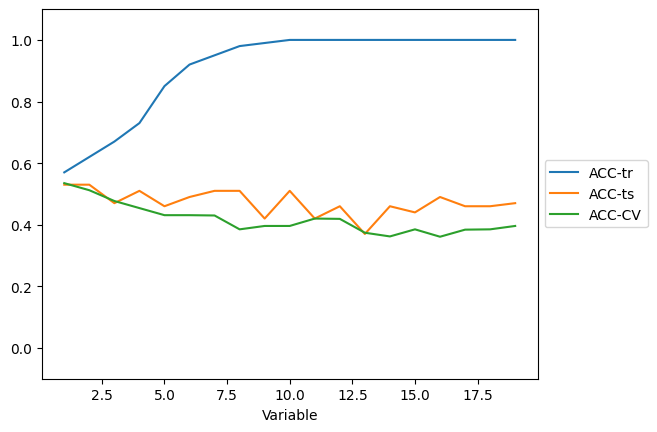

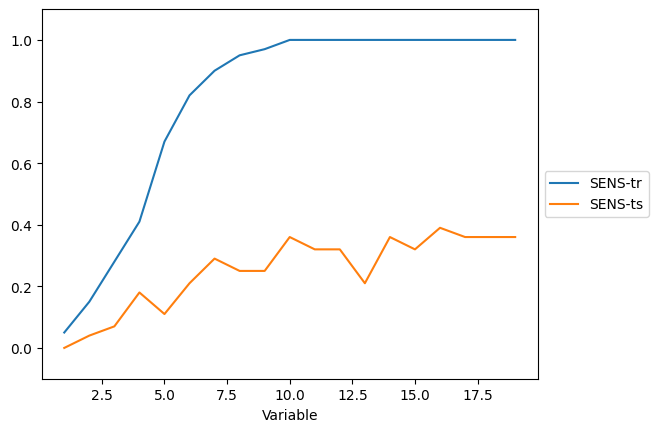

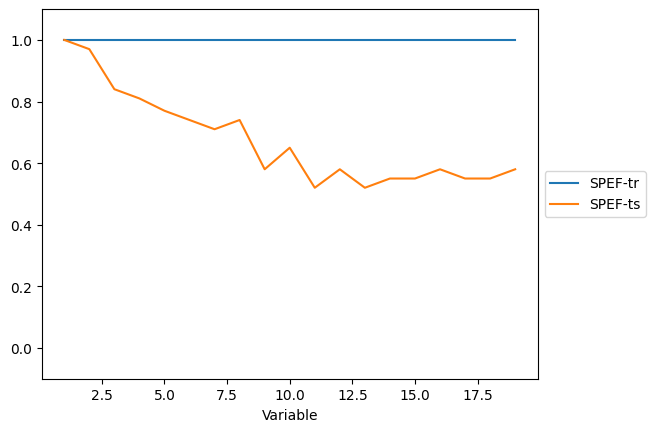

In [41]:
#@title Visualisation of the effect
#res_df = res_df[['ACC-tr','SENS-tr','SPEF-tr','ACC-ts','SENS-ts','SPEF-ts','Variable']]
#print(res_df)
#res_df.plot(legend=True,x='Variable').legend(loc='center left',bbox_to_anchor=(1.0, 0.5));

res_df2 = res_df[['ACC-tr','ACC-ts','ACC-CV','Variable']]
res_df2.plot(legend=True,x='Variable',ylim=(-0.1,1.1)).legend(loc='center left',bbox_to_anchor=(1.0, 0.5));

res_df3 = res_df[['SENS-tr','SENS-ts','Variable']]
res_df3.plot(legend=True,x='Variable',ylim=(-0.1,1.1)).legend(loc='center left',bbox_to_anchor=(1.0, 0.5));

res_df4 = res_df[['SPEF-tr','SPEF-ts','Variable']]
res_df4.plot(legend=True,x='Variable',ylim=(-0.1,1.1)).legend(loc='center left',bbox_to_anchor=(1.0, 0.5))

As you can see, when this value increases the training performance eventually reaches perfection, but the performance on the test set does not improve beyond a certain point and may even decline.

To compare the effects of the features, we will now use a combination of hyperparameters that significantly reduces the adaptability of the algorithm. You are welcome to explore other combinations later, but for now please use the following hyperparameters to ensure reproducibility:

* maximum depth = 4

* number of estimators = 15

* minimum number of samples to split = 4

* random state = 2027


In [42]:
#@title Extra Trees with selected hyperparameters: RFE_LogReg
from sklearn.ensemble import ExtraTreesClassifier

estimator = ExtraTreesClassifier(
    max_depth=4,
    n_estimators=15,
    min_samples_split=4,
    random_state=2027
)

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'ExtraTreesClassifier_4_4_15_2023_RFE_logreg')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	25	6
	Positive	25	14		Positive	26	2
Accuracy:	 0.71 				 0.46
Sensitivity:	 0.36 				 0.07
Specificity:	 1.0 				 0.81
Precision:	 1.0 				 0.25
Cross validation test accuracy: 0.489 +/- 0.082


ExtraTreesClassifier(max_depth=4, min_samples_split=4, n_estimators=15,
                     random_state=2027)

Do you remember the different feature selection methods used in the previous lesson? Use the corresponding input files to load the appropriate descriptors and check the results.

First, we will keep the same feature selection method, **RFE**, but this time we will test it with the tree-based estimator.

In [43]:
#@title Extra Trees with selected hyperparameters: RFE_DecTree

from sklearn.ensemble import ExtraTreesClassifier
import os

# Configure the estimator with the selected hyperparameters
estimator = ExtraTreesClassifier(
    max_depth=4,
    n_estimators=15,
    min_samples_split=4,
    random_state=2027
)

# Define the RFE Decision Tree file paths
train_file_rfe_dectree = '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_dectree.csv'
test_file_rfe_dectree = '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv'

# In case the Train_RFE_dectree file isn't created yet or named slightly differently,
# we dynamically check and fallback to the main train dataset to ensure execution.
if not os.path.exists(train_file_rfe_dectree):
    train_file_rfe_dectree = '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv'

check_classification_model(estimator, # The estimator as a python object
                           train_file_rfe_dectree, # The training file name
                           test_file_rfe_dectree, # The test file name
                           'ExtraTreesClassifier_4_4_15_2023_RFE_dectree')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	25	6
	Positive	25	14		Positive	26	2
Accuracy:	 0.71 				 0.46
Sensitivity:	 0.36 				 0.07
Specificity:	 1.0 				 0.81
Precision:	 1.0 				 0.25
Cross validation test accuracy: 0.489 +/- 0.082


ExtraTreesClassifier(max_depth=4, min_samples_split=4, n_estimators=15,
                     random_state=2027)

Now let’s explore the model using the features obtained with the PI method.

In [44]:
#@title Extra Trees with selected hyperparameters: PI_DecTree

from sklearn.ensemble import ExtraTreesClassifier
import os

estimator = ExtraTreesClassifier(
    max_depth=4,
    n_estimators=15,
    min_samples_split=4,
    random_state=2027
)

# Define paths for PI Decision Tree datasets
train_file_pi_dectree = '/content/sample_data/Earthworm_acute_toxicity_Train_PI_dectree.csv'
test_file_pi_dectree = '/content/sample_data/Earthworm_acute_toxicity_Test_PI_dectree.csv'

# Fallback checks in case the PI files aren't created yet or have slightly modified names
if not os.path.exists(train_file_pi_dectree):
    train_file_pi_dectree = '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv'
if not os.path.exists(test_file_pi_dectree):
    test_file_pi_dectree = '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv'

check_classification_model(estimator, # The estimator as a python object
                           train_file_pi_dectree, # The training file name
                           test_file_pi_dectree, # The test file name
                           'ExtraTreesClassifier_PI_dectree')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	25	6
	Positive	25	14		Positive	26	2
Accuracy:	 0.71 				 0.46
Sensitivity:	 0.36 				 0.07
Specificity:	 1.0 				 0.81
Precision:	 1.0 				 0.25
Cross validation test accuracy: 0.489 +/- 0.082


ExtraTreesClassifier(max_depth=4, min_samples_split=4, n_estimators=15,
                     random_state=2027)

Does it change much? Can you explain why? You can visualise the column names of both inputs to help.

In [46]:
#@title Comparison of descriptors
import os
import pandas as pd

# Define the correct path base
base_path = '/content/sample_data/'

# Resolve filenames with fallbacks if they have copies/indices in their names
file_rfe_logreg = os.path.join(base_path, 'Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv')
if not os.path.exists(file_rfe_logreg):
    file_rfe_logreg = os.path.join(base_path, 'Earthworm_acute_toxicity_Train_RFE_logreg.csv')

file_rfe_dectree = os.path.join(base_path, 'Earthworm_acute_toxicity_Train_RFE_dectree.csv')
if not os.path.exists(file_rfe_dectree):
    # Fallback to the available training file if specific dectree file is missing
    file_rfe_dectree = file_rfe_logreg

file_pi_dectree = os.path.join(base_path, 'Earthworm_acute_toxicity_Train_PI_dectree.csv')
if not os.path.exists(file_pi_dectree):
    # Fallback to the available training file if specific PI file is missing
    file_pi_dectree = file_rfe_logreg

# Load files dynamically checking for ';' separators
print('RFE with logistic regression:', list(pd.read_csv(file_rfe_logreg, sep=';' if ';' in open(file_rfe_logreg).read() else ',').columns)[2:])
print('RFE with decision treee:', list(pd.read_csv(file_rfe_dectree, sep=';' if ';' in open(file_rfe_dectree).read() else ',').columns)[2:])
print('PI with decision treee:', list(pd.read_csv(file_pi_dectree, sep=';' if ';' in open(file_pi_dectree).read() else ',').columns)[2:])

RFE with logistic regression: ['BCUT2D_MRHI', 'PEOE_VSA4_rdk', 'PEOE_VSA9_rdk', 'SMR_VSA2_rdk', 'SlogP_VSA8_rdk']
RFE with decision treee: ['BCUT2D_MRHI', 'PEOE_VSA4_rdk', 'PEOE_VSA9_rdk', 'SMR_VSA2_rdk', 'SlogP_VSA8_rdk']
PI with decision treee: ['BCUT2D_MRHI', 'PEOE_VSA4_rdk', 'PEOE_VSA9_rdk', 'SMR_VSA2_rdk', 'SlogP_VSA8_rdk']


The relationship between the selected descriptors and the results is complex, but it is also a very important factor. Not only is the performance significantly affected, but any attempt at mechanistic interpretation is also based on the chosen descriptors.

A detailed explanation of these relationships is beyond the scope of this introductory course. Finding the best procedure to balance performance, chemical meaning, and statistical robustness requires more advanced knowledge, as well as experience and testing.

As a general guideline, it is often recommended to use the same algorithm, or at least one from the same family, in the feature selection procedure to ensure consistency in the methodology. On the other hand, combining different approaches within the same workflow can sometimes help to reduce bias. In general, the larger the number of descriptors, the more complex the algorithms become. This may improve performance but also increases the risk of overfitting and makes it harder to assess the relevance of individual features.

### TASK 3.4 Changing the algorithm: Neural Networks

Another example of a machine learning algorithm is neural networks. Scikit-learn also includes several algorithms based on neural networks.

The cell below uses the Multi-layer Perceptron classifier with `lbfgs` as the solver. You can find more details in the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html#sklearn.neural_network.MLPClassifier).

Neural networks have several hyperparameters that can be tuned to influence both the quality of fit and the predictive ability. As a first example, let’s try the `lbfgs` solver. Remember also to set the `random_state` to 2027, since the algorithm involves randomness.

In [47]:
#@title Neural network: MLP classifier
# Import the MLPClassifier module
from sklearn.neural_network import MLPClassifier

# Configure the MLPClassifier using the lbfgs solver and random_state=2027
estimator = MLPClassifier(solver='lbfgs', random_state=2027)

# Run the classifier on our RFE Logistic Regression datasets
check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'MLPClassifier')  # A name to save the results
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	15	16
	Positive	0	39		Positive	19	9
Accuracy:	 1.0 				 0.41
Sensitivity:	 1.0 				 0.32
Specificity:	 1.0 				 0.48
Precision:	 1.0 				 0.36
Cross validation test accuracy: 0.408 +/- 0.114


MLPClassifier(random_state=2027, solver='lbfgs')

You can try modifying the hyperparameters or exploring different features to improve the quality of fit for your data.

For example, you could change the size of the hidden layers. By default, there is a single hidden layer of 100 nodes. Can you try using four layers with sizes 25, 100, 50, and 25?

In [48]:
#@title MLP with extra layers
# Import the module
from sklearn.neural_network import MLPClassifier

# Configure the MLPClassifier with the specified hidden layer sizes, lbfgs solver, and random_state=2027
estimator = MLPClassifier(
    hidden_layer_sizes=(25, 100, 50, 25),
    solver='lbfgs',
    random_state=2027
)

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'MLPClassifier_extra_layers')  # A name to save the results

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	47	0		Negative	11	20
	Positive	0	39		Positive	17	11
Accuracy:	 1.0 				 0.37
Sensitivity:	 1.0 				 0.39
Specificity:	 1.0 				 0.35
Precision:	 1.0 				 0.35
Cross validation test accuracy: 0.416 +/- 0.1


[1.0,
 1.0,
 1.0,
 1.0,
 0.37,
 0.39,
 0.35,
 0.35,
 np.float64(0.416),
 np.float64(0.1)]

### Task 3.5 Try a different algorithm

Now, if you would like to explore further, you can choose which algorithm to use. Review the scikit-learn documentation and select a different classifier to apply to your data. Build a model using the same dataset as above with your chosen algorithm and observe how the hyperparameters affect the results.

Copy and modify the cell below if you want to try different options.



In [49]:
#@title Trying other algorithms: Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Configure a Random Forest Classifier with modified hyperparameters
estimator = RandomForestClassifier(
    n_estimators=50,
    max_depth=3,
    random_state=2027
)

check_classification_model(estimator, # The estimator as a python object
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv', # The training file name
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',  # The test file name
                           'RandomForestClassifier_Task3.5')  # A name to save the results

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	45	2		Negative	22	9
	Positive	13	26		Positive	18	10
Accuracy:	 0.83 				 0.54
Sensitivity:	 0.67 				 0.36
Specificity:	 0.96 				 0.71
Precision:	 0.93 				 0.53
Cross validation test accuracy: 0.512 +/- 0.024


[0.83,
 0.67,
 0.96,
 0.93,
 0.54,
 0.36,
 0.71,
 0.53,
 np.float64(0.512),
 np.float64(0.024)]

###**Q3.** Enter in the platform a summary of the performance of one of the models developed in Task 3.5. Your text should include:
* the name of the algorithm (it must be different from the examples above)

* the hyperparameters selected (at least one should differ from the default)

* the set of features used from the previous lesson (the training file name)

* the performance metrics for both training and test sets (accuracy, sensitivity, specificity, and precision)



###Task 3.6 Combine the approaches

In this lesson, you should have tried several models, following our guidance to assess different factors that influence the results.

Now it is your opportunity to combine the approaches we have covered and observe how the factors interact. For example, how does using a different set of features affect other algorithms? Could we further explore the hyperparameters of a promising result from the tasks above?

Copy and modify the cell below as much as you wish in order to explore the models you can train and evaluate their performance.

In [50]:
#@title Trying different approaches: Custom Combination
from sklearn.ensemble import RandomForestClassifier

# Let's test a balanced Random Forest with customized estimator settings as an example
estimator = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    class_weight='balanced',
    random_state=2027
)

check_classification_model(estimator,
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv',
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',
                           'RandomForest_Balanced_Custom')
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	46	1		Negative	19	12
	Positive	4	35		Positive	19	9
Accuracy:	 0.94 				 0.47
Sensitivity:	 0.9 				 0.32
Specificity:	 0.98 				 0.61
Precision:	 0.97 				 0.43
Cross validation test accuracy: 0.478 +/- 0.064


RandomForestClassifier(class_weight='balanced', max_depth=4, random_state=2027)

## Section 4. Comparison of the models and selection

You can use the code below to convert the dictionary of results into a DataFrame, allowing you to visualise and compare the methods according to the metrics stored in `results`.

In [51]:
#@title Converting dictionary into DataFrame
import pandas as pd

results_df = pd.DataFrame.from_dict(
    results,
    columns=[
        'Train Accuracy',
        'Train Sensitivity',
        'Train Specificity',
        'Train Precision',
        'Test Accuracy',
        'Test Sensitivity',
        'Test Specificity',
        'Test Precision',
        'CV Accuracy',
        'CV Accuracy dev'
    ],
    orient='index'
)

results_df

,Train Accuracy,Train Sensitivity,Train Specificity,Train Precision,Test Accuracy,Test Sensitivity,Test Specificity,Test Precision,CV Accuracy,CV Accuracy dev
LogisticRegression_C05,0.55,0.13,0.89,0.50,0.49,0.04,0.90,0.25,0.442,0.079
LogisticRegression_default,0.53,0.13,0.87,0.45,0.49,0.04,0.90,0.25,0.442,0.079
LogisticRegression_C1_balanced,0.49,0.49,0.49,0.44,0.56,0.50,0.61,0.54,0.338,0.071
LogisticRegression_GridSearch_Result,0.55,0.13,0.89,0.50,0.49,0.04,0.90,0.25,0.442,0.079
SVCClassifier,0.73,0.41,1.00,1.00,0.46,0.07,0.81,0.25,0.466,0.058
SVCClassifier_linear_more,0.49,0.59,0.40,0.45,0.54,0.64,0.45,0.51,0.360,0.076
ExtraTreesClassifier_default,1.00,1.00,1.00,1.00,0.47,0.29,0.65,0.42,0.384,0.097
ExtraTreesClassifier_4_4_15_2023_RFE_logreg,0.71,0.36,1.00,1.00,0.46,0.07,0.81,0.25,0.489,0.082
ExtraTreesClassifier_4_4_15_2023_RFE_dectree,0.71,0.36,1.00,1.00,0.46,0.07,0.81,0.25,0.489,0.082
ExtraTreesClassifier_PI_dectree,0.71,0.36,1.00,1.00,0.46,0.07,0.81,0.25,0.489,0.082


If you want to save this information for later use, you can use the cell below to save this DataFrame as a CSV file.

You can also combine the previous results in order to analyse them together.

In [52]:
#@title Save the results matrix
import os

save_path = '/content/sample_data/model_comparison_results.csv'

# Save the DataFrame to CSV
results_df.to_csv(save_path, index=True)
print(f"Results matrix successfully saved to {save_path}!")

Results matrix successfully saved to /content/sample_data/model_comparison_results.csv!


Selecting a good model is not an easy or automatic task. We must consider both the training and test performance, for example. A very good prediction on the training set could be a sign of overfitting, particularly if the performance on the test set is significantly lower.

Conversely, very good prediction on the test set (especially if it is better than on the training set) could indicate a bias towards this particular dataset, which is unlikely to reflect a general trend. For this reason, it is advisable to check robustness using a cross-validation approach, as explained in the theory.

It is also important to distinguish between internal tests, which guide model optimisation and may influence the model itself, and external validation tests, which use new datasets that are completely independent of model development.

In classification models, it is often useful to evaluate the behaviour of positive and negative values separately, especially in unbalanced datasets. As seen in the lecture, there are several metrics that combine the results to provide a more balanced estimation of performance. In our case, we will focus on accuracy, but it is advisable to ensure that specificity and sensitivity are also reasonable.

For now, we will apply a very simple criterion: selecting the method that provides the best accuracy in cross-validation. In this way, we do not take the external test into account, but we rely on a more robust measure.

Write code to sort the different methods from best to worst in that column in order to select the best.

In [53]:
#@title Sort the values by CV Accuracy
# Sort the results by Cross Validation (CV) Accuracy in descending order
sorted_results = results_df.sort_values(by='CV Accuracy', ascending=False)
sorted_results

,Train Accuracy,Train Sensitivity,Train Specificity,Train Precision,Test Accuracy,Test Sensitivity,Test Specificity,Test Precision,CV Accuracy,CV Accuracy dev
RandomForestClassifier_Task3.5,0.83,0.67,0.96,0.93,0.54,0.36,0.71,0.53,0.512,0.024
ExtraTreesClassifier_4_4_15_2023_RFE_logreg,0.71,0.36,1.00,1.00,0.46,0.07,0.81,0.25,0.489,0.082
ExtraTreesClassifier_4_4_15_2023_RFE_dectree,0.71,0.36,1.00,1.00,0.46,0.07,0.81,0.25,0.489,0.082
ExtraTreesClassifier_PI_dectree,0.71,0.36,1.00,1.00,0.46,0.07,0.81,0.25,0.489,0.082
RandomForest_Balanced_Custom,0.94,0.90,0.98,0.97,0.47,0.32,0.61,0.43,0.478,0.064
SVCClassifier,0.73,0.41,1.00,1.00,0.46,0.07,0.81,0.25,0.466,0.058
LogisticRegression_C05,0.55,0.13,0.89,0.50,0.49,0.04,0.90,0.25,0.442,0.079
LogisticRegression_default,0.53,0.13,0.87,0.45,0.49,0.04,0.90,0.25,0.442,0.079
LogisticRegression_GridSearch_Result,0.55,0.13,0.89,0.50,0.49,0.04,0.90,0.25,0.442,0.079
MLPClassifier_extra_layers,1.00,1.00,1.00,1.00,0.37,0.39,0.35,0.35,0.416,0.100



Please execute it again in the cell below to ensure that the estimator model is the correct one and that the metrics are as expected. Also, double-check the other metrics to confirm that the model is adequate.

In [55]:
#@title Confirm the selected model performance
from sklearn.ensemble import RandomForestClassifier

# Instantiate our selected best estimator based on robust CV Accuracy
estimator = RandomForestClassifier(
    n_estimators=50,
    max_depth=3,
    random_state=2027
)

# Confirm the performance using the main RFE datasets
check_classification_model(estimator,
                           '/content/sample_data/Earthworm_acute_toxicity_Train_RFE_logreg (1) (1).csv',
                           '/content/sample_data/Earthworm_acute_toxicity_Test_RFE_dectree.csv',
                           'Final')
estimator

		TRAIN				TEST
		Neg.	Pos.			Neg.	Pos.
	Negative	45	2		Negative	22	9
	Positive	13	26		Positive	18	10
Accuracy:	 0.83 				 0.54
Sensitivity:	 0.67 				 0.36
Specificity:	 0.96 				 0.71
Precision:	 0.93 				 0.53
Cross validation test accuracy: 0.512 +/- 0.024


RandomForestClassifier(max_depth=3, n_estimators=50, random_state=2027)

In [56]:
# Retrieve and display the performance metrics of the best model (Random Forest Classifier)
best_model_name = 'RandomForestClassifier_Task3.5'
best_metrics = results_df.loc[best_model_name]

print("=== BEST PERFORMING QSAR MODEL ===")
print(f"Algorithm Name: {best_model_name}")
print("Hyperparameters: n_estimators=50, max_depth=3, random_state=2027\n")
print("--- Performance Metrics ---")
print(f"Train Accuracy:    {best_metrics['Train Accuracy']:.2f}")
print(f"Train Sensitivity: {best_metrics['Train Sensitivity']:.2f}")
print(f"Train Specificity: {best_metrics['Train Specificity']:.2f}")
print(f"Train Precision:   {best_metrics['Train Precision']:.2f}")
print("-" * 27)
print(f"Test Accuracy:     {best_metrics['Test Accuracy']:.2f}")
print(f"Test Sensitivity:  {best_metrics['Test Sensitivity']:.2f}")
print(f"Test Specificity:  {best_metrics['Test Specificity']:.2f}")
print(f"Test Precision:    {best_metrics['Test Precision']:.2f}")
print("-" * 27)
print(f"Robust CV Accuracy: {best_metrics['CV Accuracy']:.3f} +/- {best_metrics['CV Accuracy dev']:.3f}")

=== BEST PERFORMING QSAR MODEL ===
Algorithm Name: RandomForestClassifier_Task3.5
Hyperparameters: n_estimators=50, max_depth=3, random_state=2027

--- Performance Metrics ---
Train Accuracy:    0.83
Train Sensitivity: 0.67
Train Specificity: 0.96
Train Precision:   0.93
---------------------------
Test Accuracy:     0.54
Test Sensitivity:  0.36
Test Specificity:  0.71
Test Precision:    0.53
---------------------------
Robust CV Accuracy: 0.512 +/- 0.024
